<img src="./src/LogoUTNNegro.png" align="right" width="150">

#### Teoría de los Circuitos 2

# Trabajo Práctico de Labotatorio 2
#### Renzo Villani

### Introducción

El procesamiento digital de señales permite reemplazar filtros analógicos por algoritmos ejecutados en un microcontrolador. En el presente trabajo se implementaron dos filtros digitales sobre una placa NUCLEO-F446RE (STM32), siguiendo la cadena de adquisición clásica: filtro antialias, conversión A/D, filtrado digital, conversión D/A y filtro de interpolación.

<center><img src="./src/img1_LAB2.png"></center>
- El filtro A se realizó como filtro IIR (arm_biquad_cascade_df1_f32).

<center><img src="./src/img2_LAB2.png"></center>
- El filtro B se realizó como filtro FIR (arm_fir_f32).

En la etapa de análisis previo se obtuvieron los coeficientes y se simuló en Python la función transferencia para una frecuencia de muestreo configurable. Luego se implementaron los filtros en el STM32 y se verificó su respuesta mediante mediciones con generador de funciones, osciloscopio y analizador de espectros.

[-2.47757708e-04 -2.52169478e-04 -2.58154179e-04 -2.65691169e-04
 -2.74663821e-04 -2.84912229e-04 -2.96171132e-04 -3.08131147e-04
 -3.20369711e-04 -3.32424127e-04 -3.43712353e-04 -3.53621544e-04
 -3.61414966e-04 -3.66340164e-04 -3.67517656e-04 -3.64073380e-04
 -3.55004101e-04 -3.39339403e-04 -3.15977934e-04 -2.83884918e-04
 -2.41892432e-04 -1.88939280e-04 -1.23827420e-04 -4.55120547e-05
  4.71949110e-05  1.55275463e-04  2.79865567e-04  4.21835863e-04
  5.82227590e-04  7.61750966e-04  9.61311298e-04  1.18141042e-03
  1.42277978e-03  1.68566757e-03  1.97059865e-03  2.27752656e-03
  2.60674383e-03  2.95787388e-03  3.33096001e-03  3.72526663e-03
  4.14058127e-03  4.57578777e-03  5.03042322e-03  5.50297680e-03
  5.99275368e-03  6.49784148e-03  7.01734646e-03  7.54895375e-03
  8.09161947e-03  8.64262946e-03  9.20085582e-03  9.76318910e-03
  1.03285031e-02  1.08932931e-02  1.14565436e-02  1.20143426e-02
  1.25659246e-02  1.31069347e-02  1.36370374e-02  1.41513568e-02
  1.46502311e-02  1.51281

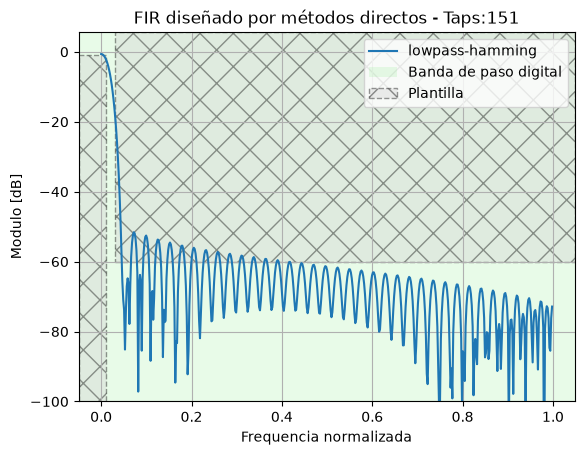

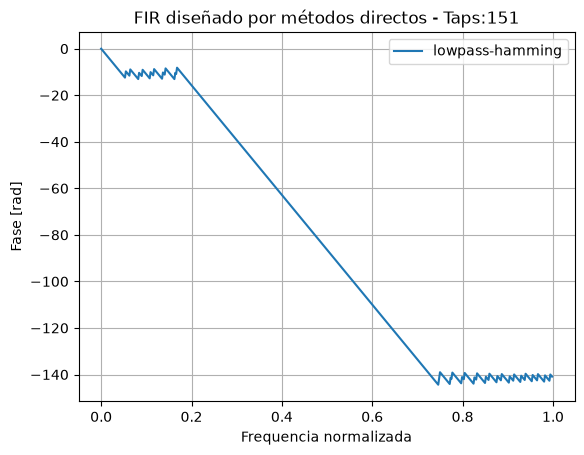

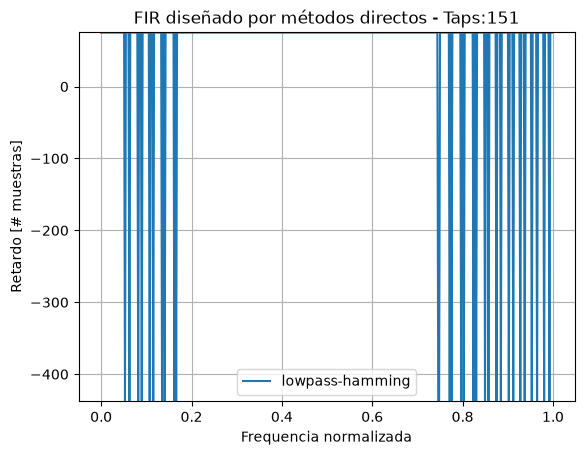

In [1]:
import sympy as sp
import numpy as np
import scipy.signal as sig
from scipy.signal.windows import hamming, kaiser, blackmanharris
import matplotlib.pyplot as plt

from pytc2.sistemas_lineales import plot_plantilla, group_delay

# frecuencia de muestreo normalizada
fs = 20*10**3
# tamaño de la respuesta al impulso
cant_coef = 151

filter_type = 'lowpass'

fpass = 100 # 
ripple = 1 # dB
fstop = 300 # Hz
attenuation = 60 # dB

f_predist = 60  #Hz

# construyo la plantilla de requerimientos
frecs = [0.0,  fpass + f_predist,   fstop - f_predist ,   fs/2]
gains = [0,   -ripple, -attenuation,   -np.inf] # dB

gains = 10**(np.array(gains)/20)


# FIR design
#num_bh = sig.firwin2(cant_coef, frecs, gains , window='blackmanharris' , 1000)
num_hm = sig.firwin2(cant_coef, frecs, gains , window='hamming', fs=fs)
#num_ka = sig.firwin2(cant_coef, frecs, gains , window=('kaiser',14) , fs=f1/2
                     
den = 1.0



def plot_freq_resp_fir(this_num, this_desc):

    wrad, hh = sig.freqz(this_num, 1.0)
    ww = wrad / np.pi
    
    plt.figure(1)

    plt.plot(ww, 20 * np.log10(abs(hh)), label=this_desc)

    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef) )
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Modulo [dB]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    
    plt.figure(2)

    phase = np.unwrap(np.angle(hh))

    plt.plot(ww, phase, label=this_desc)

    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef))
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Fase [rad]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()

    plt.figure(3)

    # ojo al escalar Omega y luego calcular la derivada.
    gd_win = group_delay(wrad, phase)

    plt.plot(ww, gd_win, label=this_desc)

    plt.ylim((np.min(gd_win[2:-2])-1, np.max(gd_win[2:-2])+1))
    plt.title('FIR diseñado por métodos directos - Taps:' + str(cant_coef))
    plt.xlabel('Frequencia normalizada')
    plt.ylabel('Retardo [# muestras]')
    plt.grid(which='both', axis='both')

    axes_hdl = plt.gca()
    axes_hdl.legend()    

plt.close('all')

#plot_freq_resp_fir(num_bh, filter_type+ '-blackmanharris')    
plot_freq_resp_fir(num_hm, filter_type+ '-hamming')    
#plot_freq_resp_fir(num_ka, filter_type+ '-kaiser-b14')    
    
    
# sobreimprimimos la plantilla del filtro requerido para mejorar la visualización    
fig = plt.figure(1)    
plot_plantilla(filter_type = filter_type , fpass = fpass/(fs/2), ripple = ripple , fstop = fstop/(fs/2), attenuation = attenuation, fs = fs)
ax = plt.gca()
ax.legend()

# reordenamos las figuras en el orden habitual: módulo-fase-retardo
plt.figure(2)    
axes_hdl = plt.gca()
axes_hdl.legend()

plt.figure(3)    
axes_hdl = plt.gca()
axes_hdl.legend()

print(num_hm)

plt.show()

SOS:
[[ 0.99984295 -1.99943919  0.99984295  1.         -1.99943919  0.99968589]]


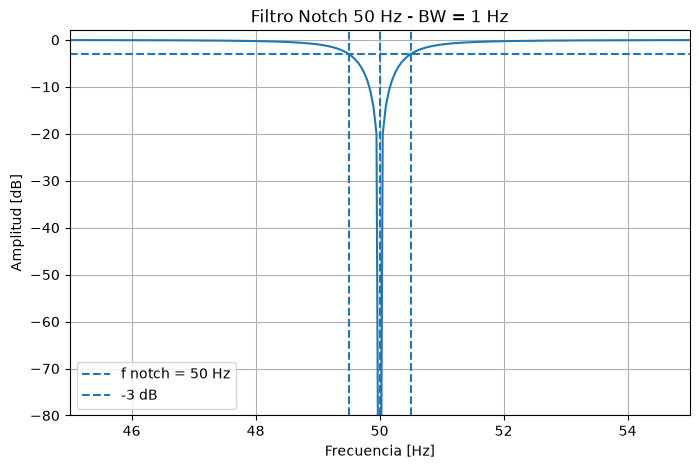

In [6]:
import numpy as np
from scipy import signal as sig
import sympy as sp
from matplotlib import pyplot as plt
from pytc2.sistemas_lineales import bodePlot, pzmap, GroupDelay, analyze_sys
from pytc2.sistemas_lineales import pretty_print_lti



# Especificaciones
f0 = 50.0
BW = 1.0
fs_muestreo = 20000.0

# Factor de calidad
Q = f0 / BW

# Filtro notch
b, a = sig.iirnotch(f0, Q, fs=fs_muestreo)

# Lo paso a SOS para trabajar igual que antes
sos = sig.tf2sos(b, a)

print("SOS:")
print(sos)

# Respuesta en frecuencia
w, h = sig.sosfreqz(
    sos,
    worN=200000,
    fs=fs_muestreo
)

plt.figure(figsize=(8,5))

plt.plot(
    w,
    20*np.log10(np.maximum(np.abs(h), 1e-8))
)

plt.axvline(f0, linestyle='--', label='f notch = 50 Hz')

# Bordes de BW de 1 Hz
plt.axvline(49.5, linestyle='--')
plt.axvline(50.5, linestyle='--')

plt.axhline(-3, linestyle='--', label='-3 dB')

plt.xlim(45, 55)
plt.ylim(-80, 2)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.title('Filtro Notch 50 Hz - BW = 1 Hz')

plt.grid(True)
plt.legend()
plt.show()